In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from PIL import Image


numpy : pour manipuler l'image sous forme de tableau (matrice).

matplotlib.pyplot : pour afficher les images.

scipy.signal.convolve2d : pour appliquer des convolutions 2D entre l'image et un filtre.

PIL.Image : pour charger l’image (en niveaux de gris ici).


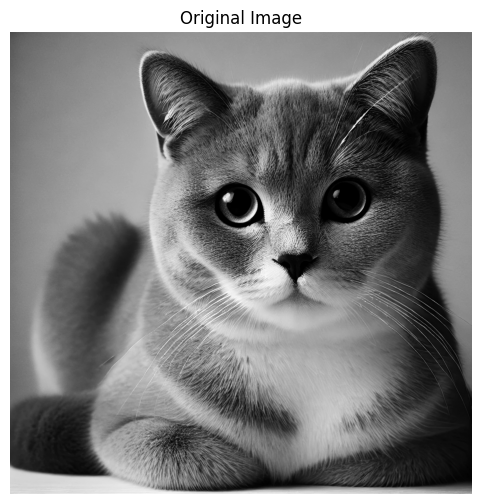

In [6]:
# Charger l'image en niveaux de gris
image_path = 'cat.png'
image = Image.open(image_path).convert('L')
image = np.array(image)

# Afficher l'image originale
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

Charge l'image 'cat.png' et la convertit en niveaux de gris ('L').

Convertit ensuite l'image en matrice NumPy.

Affiche l’image originale avec une échelle de gris (cmap='gray').

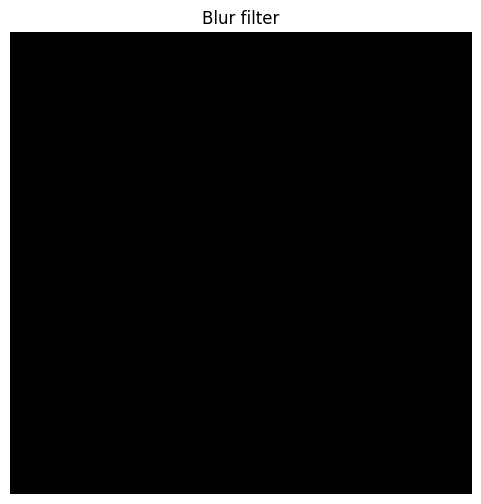

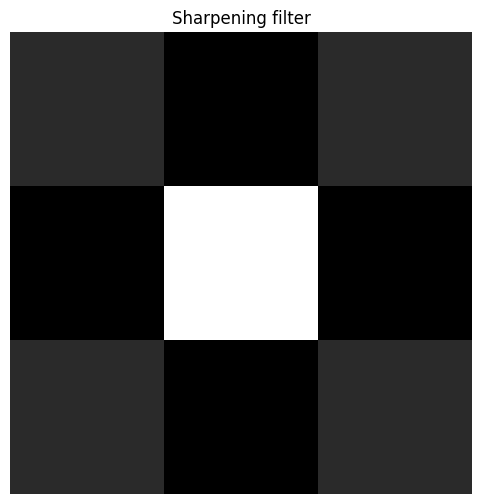

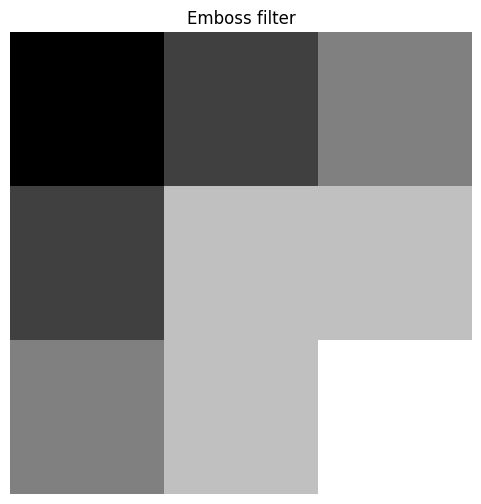

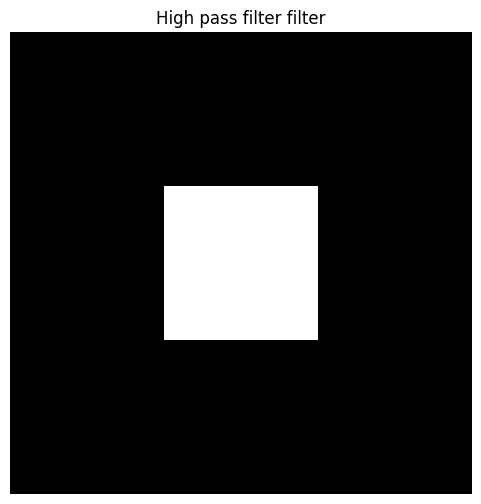

In [7]:
# Définir différents kernels
kernels = {
    'Blur': np.ones((13, 13)) / 100,  # Kernel moyen pour flouter l'image
    'Sharpening': np.array([[0, -1, 0],
                            [-1, 5, -1],
                            [0, -1, 0]]),
    'Emboss': np.array([[-2, -1, 0],
                        [-1, 1, 1],
                        [0, 1, 2]]),
    'High pass filter': np.array([[-1, -1, -1],  # kernel rejetant les fréquences basses (zones de couleur uniforme)
                                   [-1, 8, -1],
                                   [-1, - 1, -1]])
}
# Afficher chaque kernel
for name, kernel in kernels.items():
    plt.figure(figsize=(6, 6))
    plt.imshow(kernel, cmap='gray')
    plt.title(f'{name} filter')
    plt.axis('off')
    plt.show()


Définit plusieurs filtres de convolution (kernels) :

Blur : flou, moyenne d’une grande fenêtre.

Sharpening : accentuation des bords.

Emboss : donne un effet de relief à l’image.

High-pass filter : met en évidence les contours (hautes fréquences).

Chaque filtre est affiché en tant que matrice de poids.

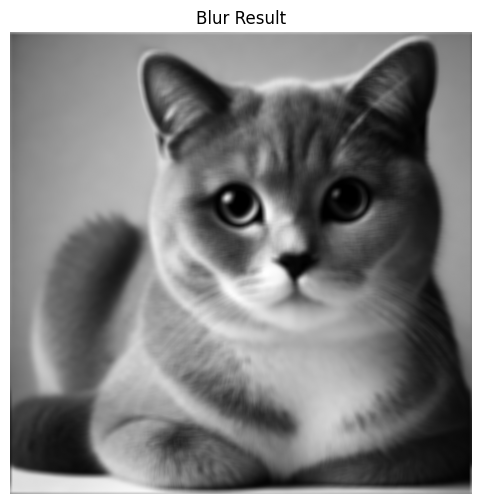

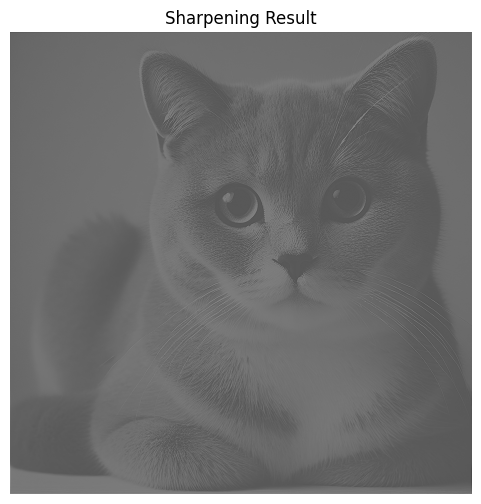

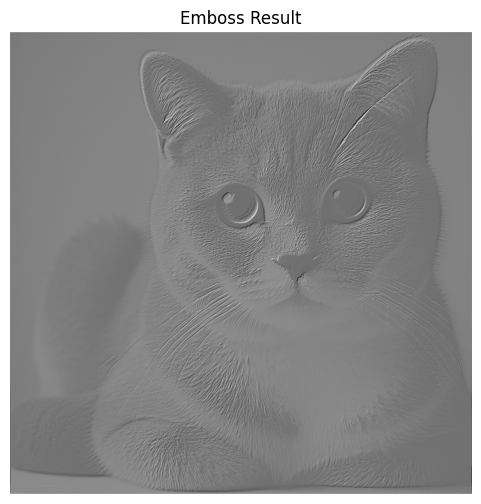

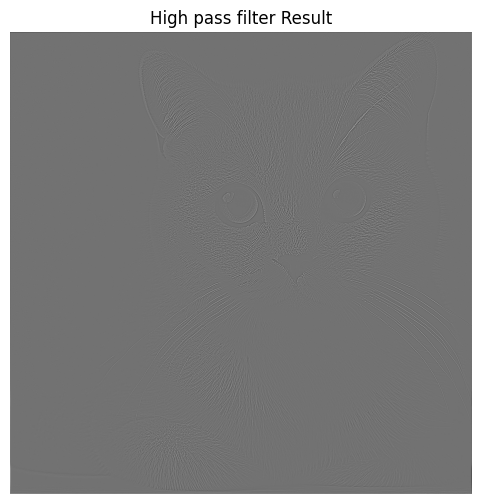

In [8]:
# Appliquer chaque kernel et afficher les résultats
for name, kernel in kernels.items():
    result = convolve2d(image, kernel, mode='same', boundary='wrap')
    plt.figure(figsize=(6, 6))
    plt.imshow(result, cmap='gray')
    plt.title(f'{name} Result')
    plt.axis('off')
    plt.show()

Applique chaque filtre à l'image avec convolve2d :

mode='same' : la sortie garde la même taille que l’image d’origine.

boundary='wrap' : la bordure est traitée comme si elle était cyclique.

Affiche le résultat visuel pour chaque filtre.